# Data Analytics Project – Module-End Assignment 5

# Social Media Engagement Analytics Using Python

In [1]:
#Task 1 – Data Import & Setup

import pandas as pd
import numpy as np


df = pd.read_csv('social_media_engagement_5000.csv')


In [2]:
# Display the first five rows
df.head()


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [3]:
# Find the number of rows and columns
df.shape


(5000, 19)

In [4]:
# Display all column names
df.columns


Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

In [5]:
# Display the data types of all columns
df.dtypes


user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object

In [6]:
#Complete dataset info

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


In [7]:
#Convert date column to datetime

df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y'
)

df['posted_at'].dtype


dtype('<M8[ns]')

In [8]:
#NumPy array operation

# Extract likes as a NumPy array
likes_array = df['likes'].to_numpy()

# Display the array
print(likes_array[:10])

[ 7011. 11750.  4862.  5350. 12682. 12535. 11703.  9611.    nan 14106.]


In [10]:

# Create a sample NumPy array
numbers = np.array([10, 20, 30, 40, 50])

# Add 5 to every element
print(numbers + 5)

# Multiply every element by 2
print(numbers * 2)

# Find the square of every element
print(numbers ** 2)


[15 25 35 45 55]
[ 20  40  60  80 100]
[ 100  400  900 1600 2500]


In [11]:
#TASK 2 – Data Cleaning

# Create a copy of the original dataset
df_clean = df.copy()


In [12]:
#Identify missing values

# Count missing values in every column
df_clean.isnull().sum()


user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [13]:
# Filling missing values

# Fill numerical missing values using median

numeric_columns = [
    'age',
    'likes',
    'comments',
    'shares'
]

for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )


# Fill categorical missing values using mode

categorical_columns = [
    'gender',
    'sentiment'
]

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].mode()[0]
    )


In [14]:
df_clean.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

In [15]:
#Duplicate Handling

df_clean.duplicated().sum()


0

In [16]:
#Data Formatting and Type Correction
#Correct numerical data types

# Convert age into integer
df_clean['age'] = df_clean['age'].round().astype(int)

# Convert engagement counts into integers
df_clean['likes'] = df_clean['likes'].round().astype(int)
df_clean['comments'] = df_clean['comments'].round().astype(int)
df_clean['shares'] = df_clean['shares'].round().astype(int)


In [17]:
#Standardising categorical values

# Standardise gender
df_clean['gender'] = (
    df_clean['gender']
    .str.strip()
    .str.lower()
    .str.title()
)

# Standardise sentiment
df_clean['sentiment'] = (
    df_clean['sentiment']
    .str.strip()
    .str.lower()
)

# Standardise post type
df_clean['post_type'] = (
    df_clean['post_type']
    .str.strip()
    .str.lower()
)

# Standardise post category
df_clean['post_category'] = (
    df_clean['post_category']
    .str.strip()
    .str.lower()
)

# Standardise device type
df_clean['device_type'] = (
    df_clean['device_type']
    .str.strip()
    .str.lower()
)

# Standardise country spacing
df_clean['country'] = df_clean['country'].str.strip()


In [19]:
#Check standardised categories

print("Gender:", df_clean['gender'].unique())

print("Sentiment:", df_clean['sentiment'].unique())

print("Post Types:", df_clean['post_type'].unique())

print("Categories:", df_clean['post_category'].unique())

print("Devices:", df_clean['device_type'].unique())


Gender: ['Female' 'Male' 'Other']
Sentiment: ['negative' 'positive' 'neutral']
Post Types: ['image' 'reel' 'text' 'video']
Categories: ['fitness' 'food' 'tech' 'travel' 'fashion' 'lifestyle' 'education'
 'music']
Devices: ['mobile' 'tablet' 'desktop']


In [20]:
#Correcting Unrealistic Values in Likes, Comments and Shares

print("Negative Likes:",
      (df_clean['likes'] < 0).sum())

print("Negative Comments:",
      (df_clean['comments'] < 0).sum())

print("Negative Shares:",
      (df_clean['shares'] < 0).sum())


Negative Likes: 0
Negative Comments: 0
Negative Shares: 0


In [21]:

print("Likes exceeding impressions:",
      (df_clean['likes'] > df_clean['impression_count']).sum())

print("Comments exceeding impressions:",
      (df_clean['comments'] > df_clean['impression_count']).sum())

print("Shares exceeding impressions:",
      (df_clean['shares'] > df_clean['impression_count']).sum())


Likes exceeding impressions: 464
Comments exceeding impressions: 65
Shares exceeding impressions: 55


In [22]:

df_clean['engagement_anomaly'] = (
    (df_clean['likes'] > df_clean['impression_count']) |
    (df_clean['comments'] > df_clean['impression_count']) |
    (df_clean['shares'] > df_clean['impression_count'])
)

# Count potential anomalies
print(df_clean['engagement_anomaly'].sum())

# Display records requiring investigation
df_clean.loc[
    df_clean['engagement_anomaly'],
    ['post_id', 'likes', 'comments', 'shares', 'impression_count']
].head(10)


467


,post_id,likes,comments,shares,impression_count
4,449706,12682,2735,1300,6019
11,538701,19856,1723,905,1816
13,287460,15700,1434,1886,389
14,110372,13850,586,650,4797
19,378427,9252,1542,139,2453
25,524477,11030,379,1979,3949
35,880985,7178,1039,1812,2314
61,151645,11234,2981,411,7845
62,915982,8496,1890,1624,1523
74,918964,16035,689,1975,14864


In [23]:
#Feature Cleaning – Extracting Hashtag Count

# Count hashtags in each post

df_clean['hashtag_count'] = (
    df_clean['hashtags']
    .str.findall(r'#\w+')
    .str.len()
)

# Display hashtags and their counts
df_clean[['hashtags', 'hashtag_count']].head(10)


,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [24]:
#Clean hashtag formatting

df_clean['hashtags'] = (
    df_clean['hashtags']
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)


In [25]:
#Cleaning Sentiment Labels

print("Available sentiment labels:")

print(df_clean['sentiment'].unique())

print("\nSentiment counts:")

print(df_clean['sentiment'].value_counts())


Available sentiment labels:
['negative' 'positive' 'neutral']

Sentiment counts:
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64


In [26]:

#final dataset dimensions
print("Dataset Shape:", df_clean.shape)

#remaining missing values
print("\nMissing Values:")
print(df_clean.isnull().sum())

#duplicate records
print("\nDuplicate Records:", df_clean.duplicated().sum())

#final data types
print("\nData Types:")
print(df_clean.dtypes)

# Display cleaned dataset
df_clean.head()


Dataset Shape: (5000, 21)

Missing Values:
user_id               0
age                   0
gender                0
country               0
post_id               0
post_type             0
post_category         0
likes                 0
comments              0
shares                0
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment             0
hashtags              0
engagement_rate       0
engagement_anomaly    0
hashtag_count         0
dtype: int64

Duplicate Records: 0

Data Types:
user_id                        int64
age                            int32
gender                        object
country                       object
post_id                        int64
post_type                     object
post_category                 object
likes                          int32
comments                       int32
shares                         int32
watch_time_sec                 int6

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,engagement_anomaly,hashtag_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,...,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,False,3
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,...,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,False,1
2,86820,32,Female,UK,109864,text,food,4862,344,955,...,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,False,1
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,...,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,False,3
4,16265,34,Other,UK,449706,image,fitness,12682,2735,1300,...,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,True,1


In [27]:
# Data Exploratioon
#Viewing Dataset Structure
#View dataset structure using head(), tail(), shape, and columns.
df_clean.head(10)

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,engagement_anomaly,hashtag_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,...,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,False,3
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,...,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,False,1
2,86820,32,Female,UK,109864,text,food,4862,344,955,...,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,False,1
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,...,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,False,3
4,16265,34,Other,UK,449706,image,fitness,12682,2735,1300,...,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,True,1
5,92386,16,Other,Canada,174310,video,tech,12535,1790,99,...,24893,2023-09-16,684761,False,desktop,positive,#fitness,0.579440,False,1
6,47194,25,Male,Japan,481598,video,travel,11703,2276,1465,...,96327,2022-04-15,519759,True,tablet,negative,#music,0.160329,False,1
7,97498,57,Female,Canada,343415,image,travel,9611,146,424,...,68446,2023-12-20,698739,False,desktop,neutral,#travel #music #fitness,0.148745,False,3
8,54131,54,Female,UK,907449,image,fashion,10106,2379,1897,...,36283,2023-07-06,615809,True,desktop,negative,#music #fun #fitness,0.533914,False,3
9,70263,62,Female,Australia,495037,video,lifestyle,14106,2480,1053,...,87972,2022-11-16,452146,False,tablet,neutral,#lifestyle #love,0.200507,False,2


In [28]:

df_clean.tail()


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,engagement_anomaly,hashtag_count
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,...,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,False,2
4996,22100,38,Other,UAE,677076,reel,education,16924,2734,1583,...,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,False,2
4997,67021,63,Female,USA,273595,text,travel,13487,1497,167,...,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,False,2
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,...,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,False,3
4999,73400,54,Other,Japan,712252,text,travel,14830,503,1798,...,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,True,3


In [29]:

df_clean.shape


(5000, 21)

In [30]:

df_clean.columns


Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'engagement_anomaly', 'hashtag_count'],
      dtype='object')

In [31]:
#Check data types and info with info() and dtypes.

df_clean.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   user_id             5000 non-null   int64         
 1   age                 5000 non-null   int32         
 2   gender              5000 non-null   object        
 3   country             5000 non-null   object        
 4   post_id             5000 non-null   int64         
 5   post_type           5000 non-null   object        
 6   post_category       5000 non-null   object        
 7   likes               5000 non-null   int32         
 8   comments            5000 non-null   int32         
 9   shares              5000 non-null   int32         
 10  watch_time_sec      5000 non-null   int64         
 11  impression_count    5000 non-null   int64         
 12  posted_at           5000 non-null   datetime64[ns]
 13  follower_count      5000 non-null   int64       

In [32]:

df_clean.dtypes


user_id                        int64
age                            int32
gender                        object
country                       object
post_id                        int64
post_type                     object
post_category                 object
likes                          int32
comments                       int32
shares                         int32
watch_time_sec                 int64
impression_count               int64
posted_at             datetime64[ns]
follower_count                 int64
is_verified                     bool
device_type                   object
sentiment                     object
hashtags                      object
engagement_rate              float64
engagement_anomaly              bool
hashtag_count                  int64
dtype: object

In [33]:
#Generate summary statistics using describe().

df_clean.describe()


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10107.012400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10106.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293014,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [34]:
#Analyze categorical distributions using value_counts(), unique(), and nunique()

# Count the number of users by gender
df_clean['gender'].value_counts()


gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64

In [35]:

# Count posts by post type
df_clean['post_type'].value_counts()


post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

In [36]:

# Count posts by sentiment
df_clean['sentiment'].value_counts()


sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

In [37]:

df_clean['post_type'].unique()


array(['image', 'reel', 'text', 'video'], dtype=object)

In [38]:

df_clean['post_type'].nunique()


4

In [39]:
print("Unique Countries:", df_clean['country'].nunique())

print("Unique Categories:", df_clean['post_category'].nunique())

print("Unique Devices:", df_clean['device_type'].nunique())

print("Unique Sentiments:", df_clean['sentiment'].nunique())

Unique Countries: 10
Unique Categories: 8
Unique Devices: 3
Unique Sentiments: 3


In [40]:
#Create a correlation matrix for numeric fields.

# Select numerical columns
numeric_df = df_clean.select_dtypes(include='number')

# Create correlation matrix
correlation_matrix = numeric_df.corr()

# Display correlation matrix
correlation_matrix


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014527,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014527,1.000000,-0.018421,0.004712,0.008711,0.007952,-0.022982,0.093520,-0.002189
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008711,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


In [41]:
#Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).
#Average likes by post type

df_clean.groupby('post_type')['likes'].mean()


post_type
image    10104.878107
reel     10037.819953
text     10100.163855
video    10188.613878
Name: likes, dtype: float64

In [42]:
#Average impressions by country

df_clean.groupby('country')['impression_count'].mean()


country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: impression_count, dtype: float64

In [43]:
#Grouping by multiple columns

df_clean.groupby(
    ['post_type', 'sentiment']
)['likes'].mean()


post_type  sentiment
image      negative      9921.959276
           neutral       9870.788114
           positive     10309.913928
reel       negative     10630.862745
           neutral       9890.804124
           positive      9890.657812
text       negative      9983.358974
           neutral       9932.030227
           positive     10253.390879
video      negative     10240.236000
           neutral      10005.907042
           positive     10272.412903
Name: likes, dtype: float64

In [44]:
#Data Wrangling 
#Merge
posts = pd.DataFrame({
    'post_id': [101, 102, 103],
    'post_type': ['Image', 'Video', 'Reel']
})

In [45]:
engagement = pd.DataFrame({
    'post_id': [101, 102, 103],
    'likes': [250, 400, 600]
})

In [46]:
merged_data = pd.merge(posts, engagement, on='post_id')

merged_data

,post_id,post_type,likes
0,101,Image,250
1,102,Video,400
2,103,Reel,600


In [47]:
#Concatenation
data1 = pd.DataFrame({
    'post_id': [101, 102],
    'likes': [250, 400]
})

data2 = pd.DataFrame({
    'post_id': [103, 104],
    'likes': [600, 300]
})
combined_data = pd.concat([data1, data2], ignore_index=True)

combined_data

,post_id,likes
0,101,250
1,102,400
2,103,600
3,104,300


In [48]:
#Join
details = pd.DataFrame({
    'post_type': ['Image', 'Video', 'Reel']
}, index=[101, 102, 103])

likes_data = pd.DataFrame({
    'likes': [250, 400, 600]
}, index=[101, 102, 103])
joined_data = details.join(likes_data)

joined_data

,post_type,likes
101,Image,250
102,Video,400
103,Reel,600


In [49]:
#Create new fields such as engagement_score, log-transformed metrics (optional), and hashtag_count.
df_clean['engagement_score'] = (
    df_clean['likes'] +
    df_clean['comments'] +
    df_clean['shares']
)

In [50]:
df_clean[['post_id', 'likes', 'comments', 'shares', 'engagement_score']].head(10)

,post_id,likes,comments,shares,engagement_score
0,496713,7011,354,1157,8522
1,157326,11750,2606,1807,16163
2,109864,4862,344,955,6161
3,848877,5350,1083,1049,7482
4,449706,12682,2735,1300,16717
5,174310,12535,1790,99,14424
6,481598,11703,2276,1465,15444
7,343415,9611,146,424,10181
8,907449,10106,2379,1897,14382
9,495037,14106,2480,1053,17639


In [51]:
df_clean['log_engagement'] = np.log1p(df_clean['engagement_score'])

In [52]:
df_clean[['engagement_score', 'log_engagement']].head(10)

,engagement_score,log_engagement
0,8522,9.050524
1,16163,9.690542
2,6161,8.726157
3,7482,8.920389
4,16717,9.724241
5,14424,9.576718
6,15444,9.645041
7,10181,9.228377
8,14382,9.573802
9,17639,9.777924


In [53]:
#Perform groupby summaries by post_type, country, and sentiment.
post_type_summary = df_clean.groupby('post_type')['engagement_score'].mean()

post_type_summary

post_type
image    12649.403368
reel     12524.049104
text     12613.259438
video    12664.608163
Name: engagement_score, dtype: float64

In [54]:
country_summary = df_clean.groupby('country')['engagement_score'].mean()

country_summary

country
Australia    12809.638945
Brazil       12385.994048
Canada       12605.906433
France       12903.397177
Germany      12635.687755
India        12492.725234
Japan        12578.658898
UAE          12757.791252
UK           12384.387424
USA          12575.473054
Name: engagement_score, dtype: float64

In [57]:
sentiment_summary = df_clean.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean'
})

sentiment_summary

,likes,comments,shares,engagement_score
sentiment,,,,
negative,10208.112500,1516.094792,1007.307292,12731.514583
neutral,9923.208906,1528.404060,996.565160,12448.178127
positive,10180.077199,1480.650617,1005.086749,12665.814564


In [58]:
#Statistical Analysis 
print("Likes Mean:", df_clean['likes'].mean())
print("Likes Median:", df_clean['likes'].median())
print("Likes Mode:", df_clean['likes'].mode()[0])

print("Comments Mean:", df_clean['comments'].mean())
print("Comments Median:", df_clean['comments'].median())
print("Comments Mode:", df_clean['comments'].mode()[0])

print("Shares Mean:", df_clean['shares'].mean())
print("Shares Median:", df_clean['shares'].median())
print("Shares Mode:", df_clean['shares'].mode()[0])

Likes Mean: 10107.0124
Likes Median: 10106.0
Likes Mode: 10106
Comments Mean: 1502.0398
Comments Median: 1497.0
Comments Mode: 1497
Shares Mean: 1002.9106
Shares Median: 1012.0
Shares Mode: 1012


In [59]:
print("Likes Standard Deviation:", df_clean['likes'].std())
print("Comments Standard Deviation:", df_clean['comments'].std())
print("Shares Standard Deviation:", df_clean['shares'].std())

Likes Standard Deviation: 5702.293013882179
Comments Standard Deviation: 856.3933120458967
Shares Standard Deviation: 570.8551999758862


In [60]:
print("Likes Variance:", df_clean['likes'].var())
print("Comments Variance:", df_clean['comments'].var())
print("Shares Variance:", df_clean['shares'].var())

Likes Variance: 32516145.616169512
Comments Variance: 733409.5049169405
Shares Variance: 325875.65933950903


In [61]:
print("25th Percentile:", np.percentile(df_clean['likes'], 25))
print("50th Percentile:", np.percentile(df_clean['likes'], 50))
print("75th Percentile:", np.percentile(df_clean['likes'], 75))
print("90th Percentile:", np.percentile(df_clean['likes'], 90))

25th Percentile: 5235.0
50th Percentile: 10106.0
75th Percentile: 14959.0
90th Percentile: 18016.300000000003


In [62]:
print("Comments 25th Percentile:", np.percentile(df_clean['comments'], 25))
print("Comments 50th Percentile:", np.percentile(df_clean['comments'], 50))
print("Comments 75th Percentile:", np.percentile(df_clean['comments'], 75))

print("Shares 25th Percentile:", np.percentile(df_clean['shares'], 25))
print("Shares 50th Percentile:", np.percentile(df_clean['shares'], 50))
print("Shares 75th Percentile:", np.percentile(df_clean['shares'], 75))

Comments 25th Percentile: 792.0
Comments 50th Percentile: 1497.0
Comments 75th Percentile: 2235.25
Shares 25th Percentile: 511.0
Shares 50th Percentile: 1012.0
Shares 75th Percentile: 1483.0


In [63]:
#calculating skewness
print("Likes Skewness:", df_clean['likes'].skew())
print("Comments Skewness:", df_clean['comments'].skew())
print("Shares Skewness:", df_clean['shares'].skew())

Likes Skewness: -0.0069015112638632775
Comments Skewness: 0.0038017289479831415
Shares Skewness: -0.014653583910311461


In [64]:
#Kurtosis
print("Likes Kurtosis:", df_clean['likes'].kurt())
print("Comments Kurtosis:", df_clean['comments'].kurt())
print("Shares Kurtosis:", df_clean['shares'].kurt())

Likes Kurtosis: -1.1499922839841221
Comments Kurtosis: -1.1443748352968992
Shares Kurtosis: -1.1468565626589917


In [65]:
#Statistical summary
statistical_summary = df_clean[
    ['likes', 'comments', 'shares', 'engagement_score']
].agg([
    'mean',
    'median',
    'std',
    'var',
    'min',
    'max'
])

statistical_summary

,likes,comments,shares,engagement_score
mean,1.010701e+04,1502.039800,1002.91060,1.261196e+04
median,1.010600e+04,1497.000000,1012.00000,1.255200e+04
std,5.702293e+03,856.393312,570.85520,5.782059e+03
var,3.251615e+07,733409.504917,325875.65934,3.343220e+07
min,1.000000e+01,0.000000,0.00000,1.930000e+02
max,1.999800e+04,2999.000000,1999.00000,2.468000e+04


In [71]:
# Data Visualization
#Import lobraries
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [67]:
#default style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [68]:
#Prepare date column
df_clean['posted_at'].dtype

dtype('<M8[ns]')

In [69]:
df_clean['year'] = df_clean['posted_at'].dt.year

df_clean['month'] = df_clean['posted_at'].dt.month

df_clean['day'] = df_clean['posted_at'].dt.day

In [70]:
df_clean[['posted_at', 'year', 'month', 'day']].head()

,posted_at,year,month,day
0,2022-12-17,2022,12,17
1,2023-06-02,2023,6,2
2,2023-05-07,2023,5,7
3,2023-02-12,2023,2,12
4,2023-05-23,2023,5,23


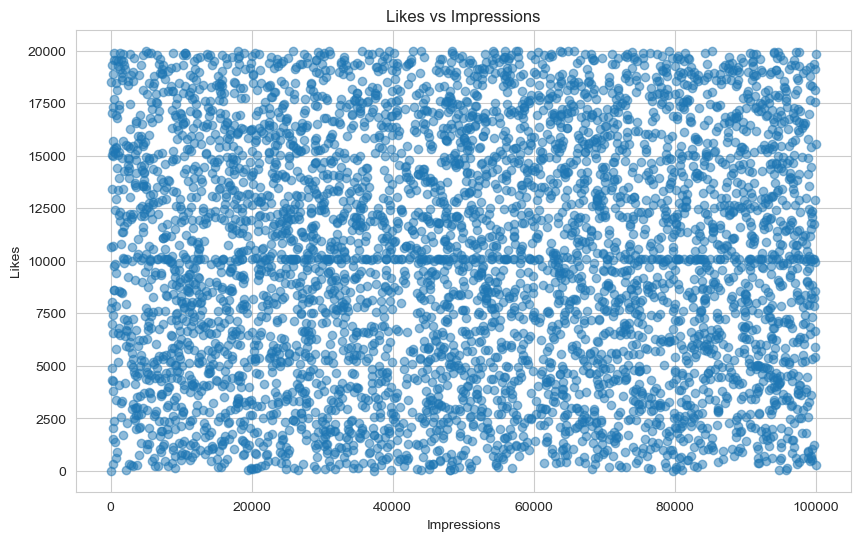

In [72]:
#Scatter Plot: Likes vs Impressions
plt.figure(figsize=(10, 6))

plt.scatter(
    df_clean['impression_count'],
    df_clean['likes'],
    alpha=0.5
)

plt.title('Likes vs Impressions')
plt.xlabel('Impressions')
plt.ylabel('Likes')

plt.show()

In [73]:
#Line Chart: Daily Engagement Trend
daily_engagement = df_clean.groupby('posted_at')['engagement_score'].sum()

daily_engagement.head()

posted_at
2022-01-01     72110
2022-01-02     96465
2022-01-03    116288
2022-01-04     31730
2022-01-05    129822
Name: engagement_score, dtype: int32

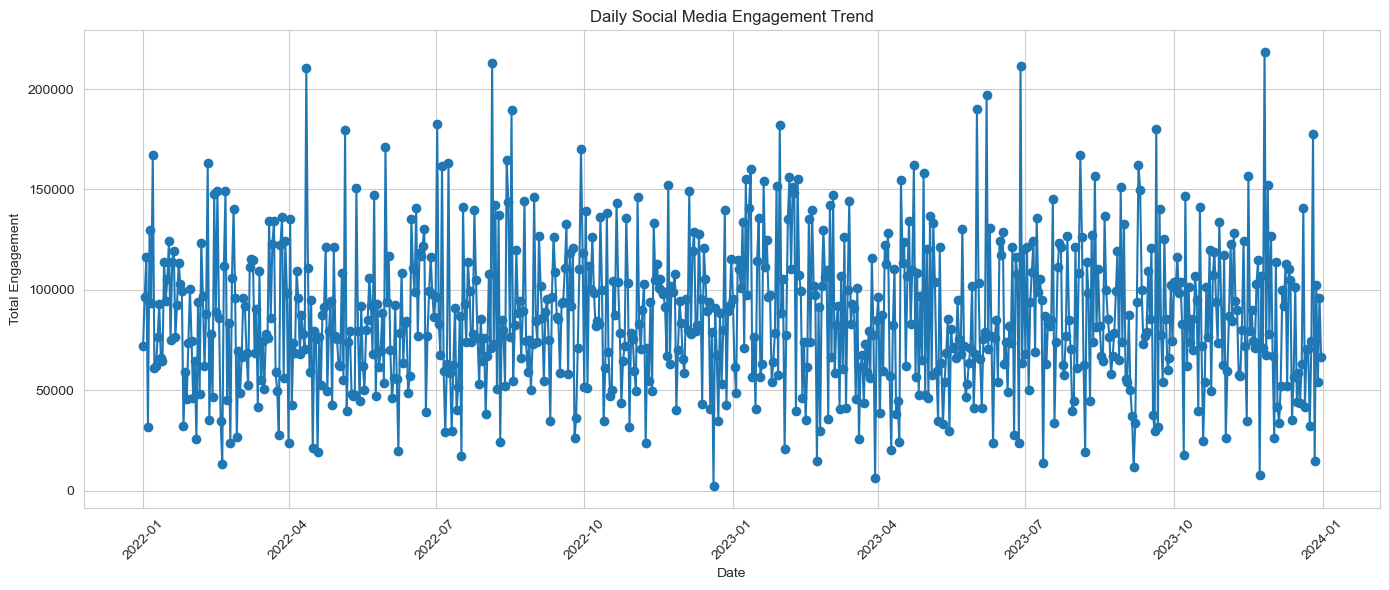

In [74]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_engagement.index,
    daily_engagement.values,
    marker='o'
)

plt.title('Daily Social Media Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Total Engagement')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

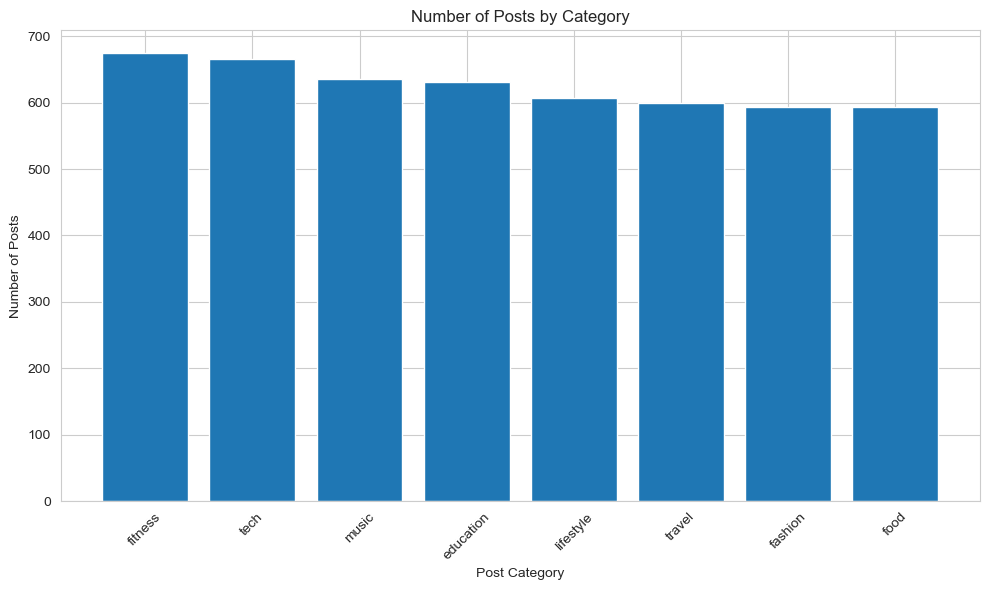

In [75]:
#Bar Chart: Posts by Category
category_counts = df_clean['post_category'].value_counts()

plt.figure(figsize=(10, 6))

plt.bar(
    category_counts.index,
    category_counts.values
)

plt.title('Number of Posts by Category')
plt.xlabel('Post Category')
plt.ylabel('Number of Posts')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

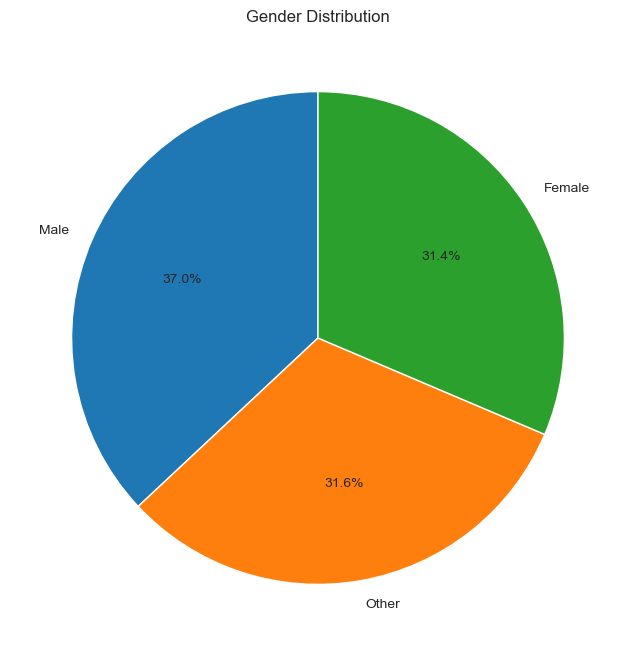

In [76]:
#Pie Chart: Gender Distribution
gender_counts = df_clean['gender'].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Gender Distribution')

plt.show()

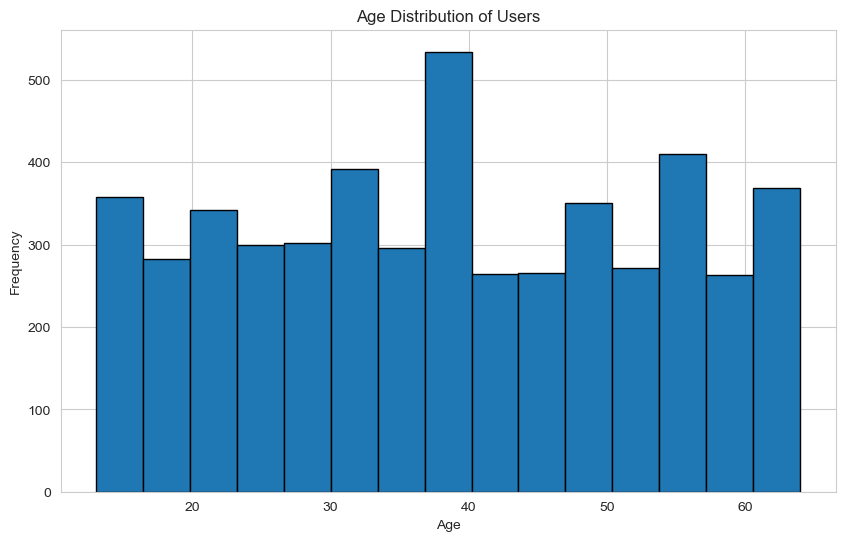

In [77]:
#Histogram: Age Distribution
plt.figure(figsize=(10, 6))

plt.hist(
    df_clean['age'].dropna(),
    bins=15,
    edgecolor='black'
)

plt.title('Age Distribution of Users')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

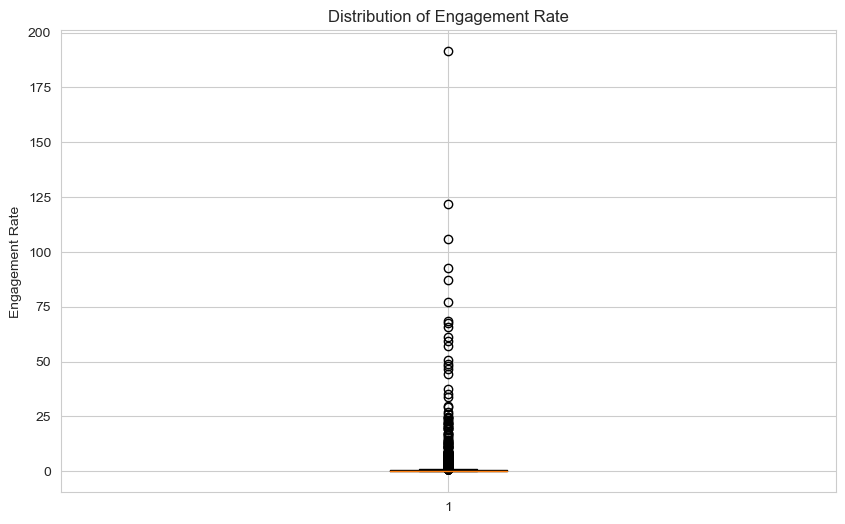

In [78]:
#Box Plot: Engagement Rate
plt.figure(figsize=(10, 6))

plt.boxplot(
    df_clean['engagement_rate'].dropna()
)

plt.title('Distribution of Engagement Rate')
plt.ylabel('Engagement Rate')

plt.show()

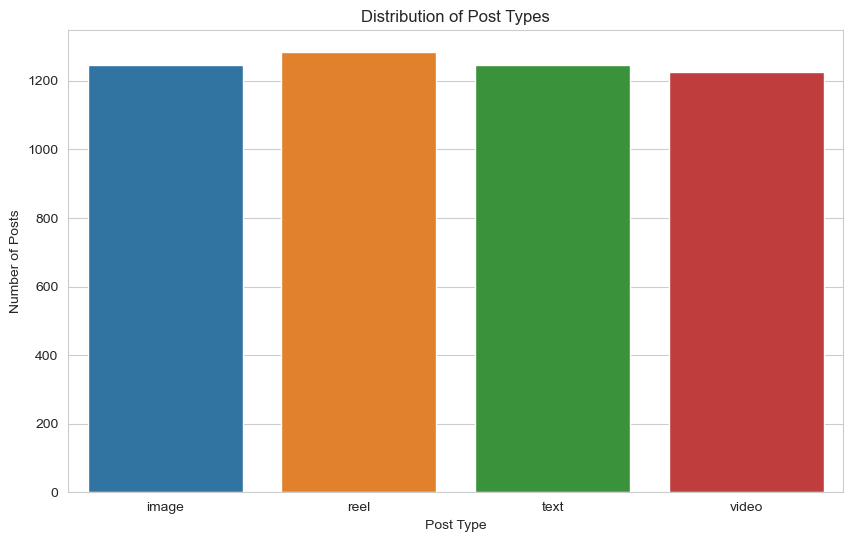

In [79]:
#Seaborn
#Count Plot: Post Type
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_clean,
    x='post_type'
)

plt.title('Distribution of Post Types')
plt.xlabel('Post Type')
plt.ylabel('Number of Posts')

plt.show()

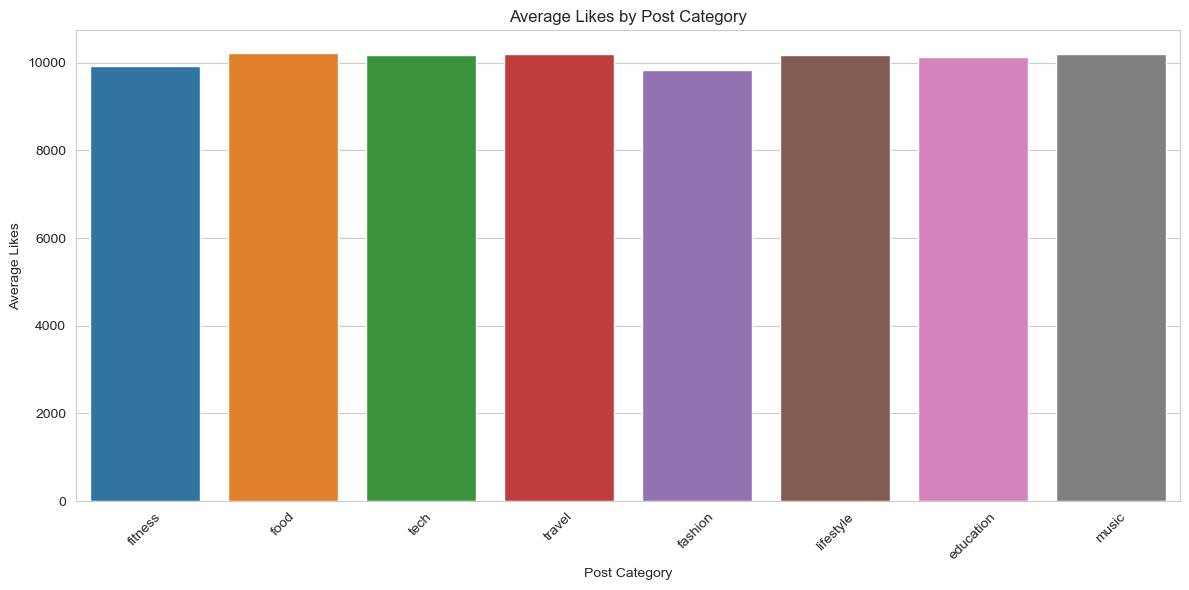

In [80]:
#Bar Plot: Average Likes by Category
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_clean,
    x='post_category',
    y='likes',
    errorbar=None
)

plt.title('Average Likes by Post Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

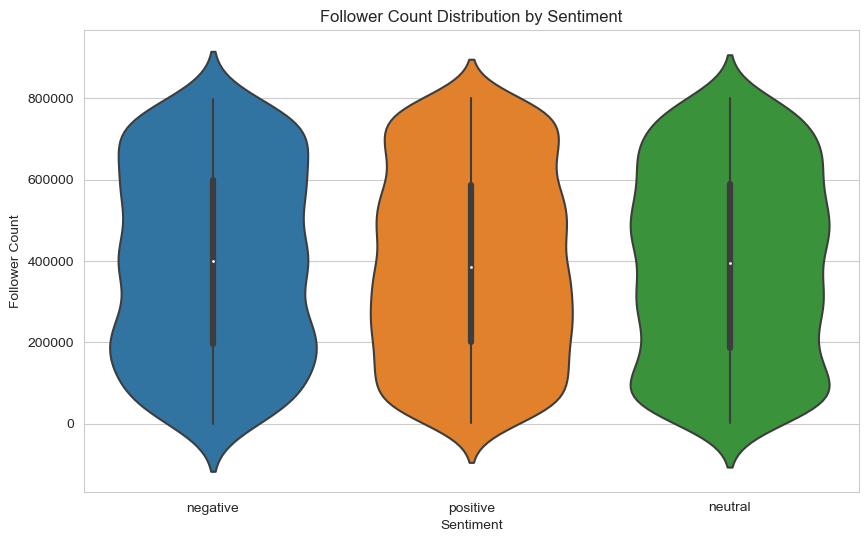

In [81]:
#Violin Plot: Followers vs Sentiment
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df_clean,
    x='sentiment',
    y='follower_count'
)

plt.title('Follower Count Distribution by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')

plt.show()

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


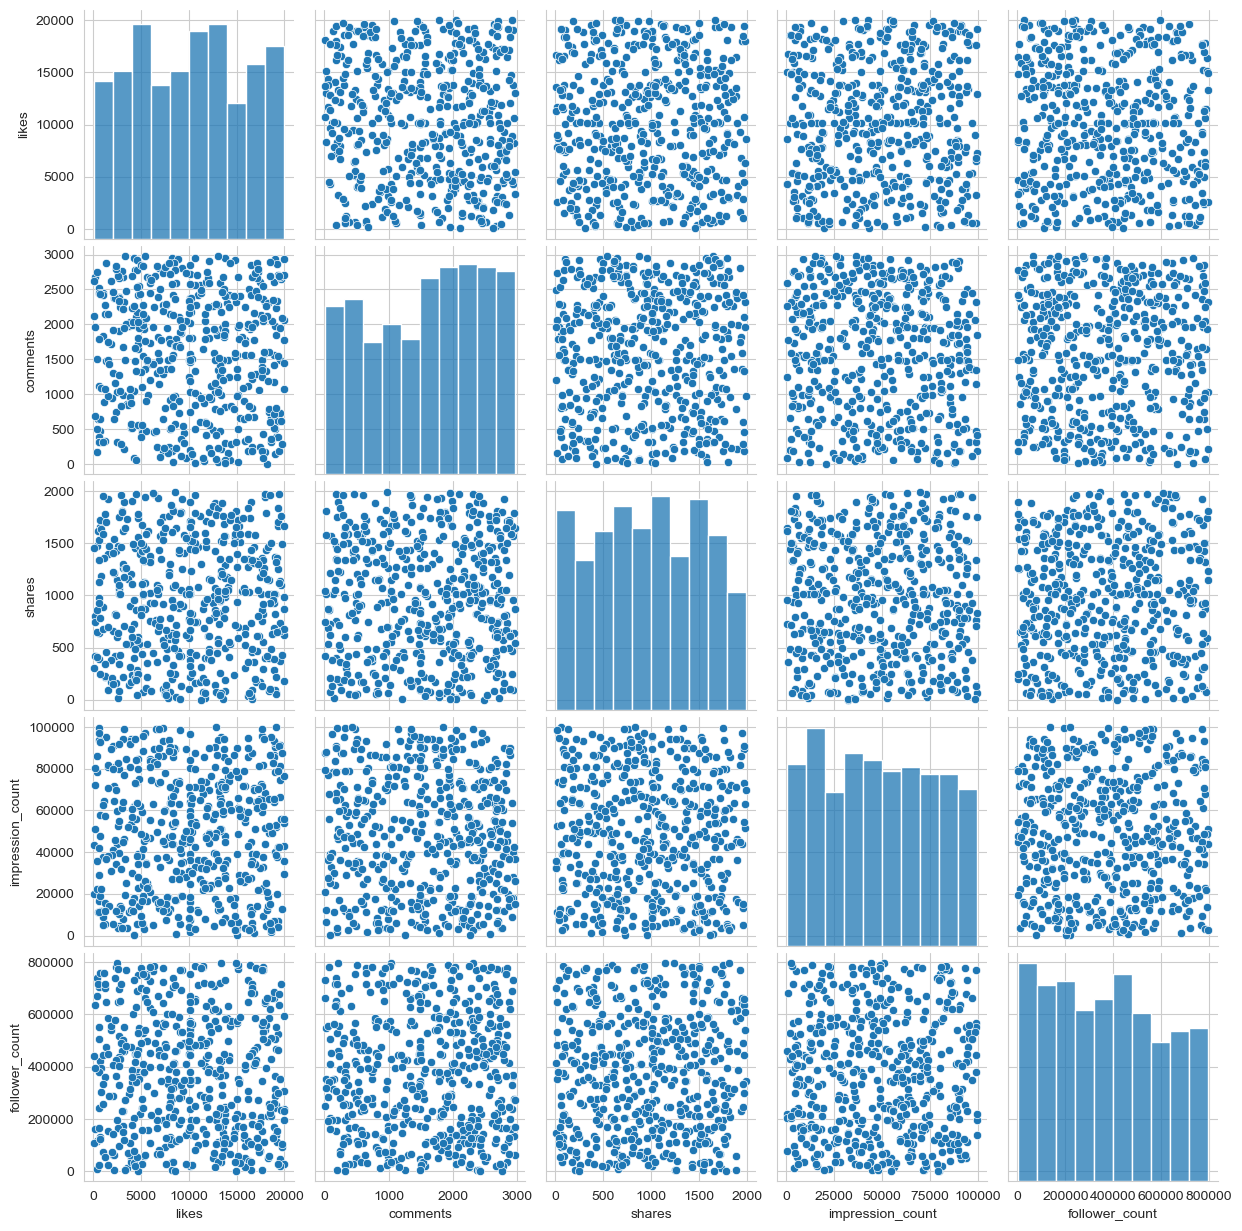

In [82]:
#Pair Plot: Numeric Features
numeric_features = [
    'likes',
    'comments',
    'shares',
    'impression_count',
    'follower_count'
]

sns.pairplot(
    df_clean[numeric_features].dropna().sample(
        n=min(500, len(df_clean)),
        random_state=42
    )
)

plt.show()

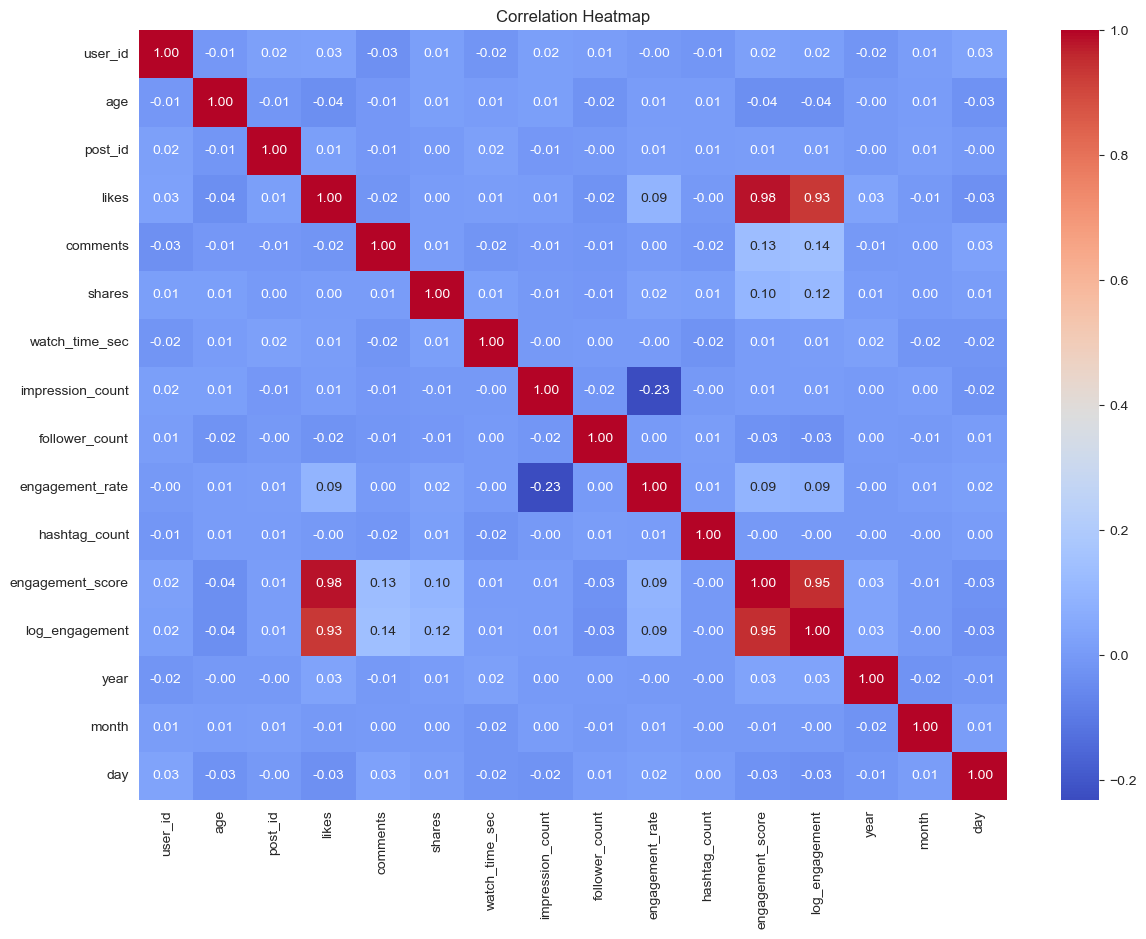

In [83]:
#Heatmap: Correlation Matrix
correlation_matrix = df_clean.select_dtypes(
    include='number'
).corr()
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

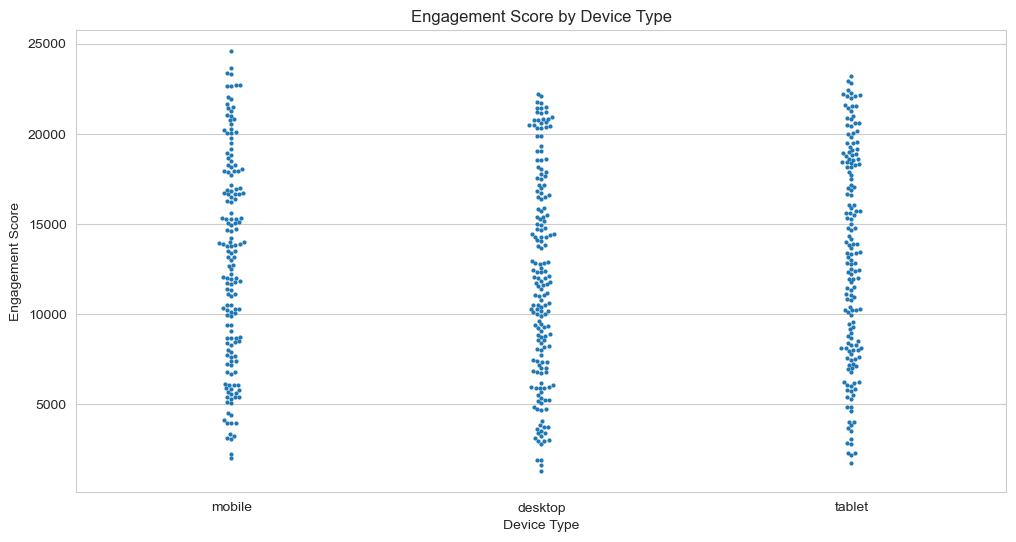

In [84]:
#Swarm Plot: Engagement vs Device
plt.figure(figsize=(12, 6))

sns.swarmplot(
    data=df_clean.sample(
        n=min(500, len(df_clean)),
        random_state=42
    ),
    x='device_type',
    y='engagement_score',
    size=3
)

plt.title('Engagement Score by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Engagement Score')

plt.show()

In [85]:
#Plotly Interactive Visualizations
#Interactive Line Chart: Daily Engagement Trend
daily_df = daily_engagement.reset_index()

fig = px.line(
    daily_df,
    x='posted_at',
    y='engagement_score',
    title='Interactive Daily Engagement Trend',
    markers=True
)

fig.show()

In [86]:
#Interactive Bar Chart: Average Engagement by Post Type
post_type_data = df_clean.groupby(
    'post_type',
    as_index=False
)['engagement_score'].mean()

In [87]:
fig = px.bar(
    post_type_data,
    x='post_type',
    y='engagement_score',
    title='Average Engagement by Post Type',
    labels={
        'post_type': 'Post Type',
        'engagement_score': 'Average Engagement'
    }
)

fig.show()

In [88]:
#Interactive Bubble Chart: Likes, Impressions and Comments
bubble_data = df_clean.sample(
    n=min(1000, len(df_clean)),
    random_state=42
)

fig = px.scatter(
    bubble_data,
    x='impression_count',
    y='likes',
    size='comments',
    color='post_type',
    hover_data=['post_id', 'shares'],
    title='Likes vs Impressions – Bubble Chart'
)

fig.show()

In [89]:
#Interactive Scatter Plot: Followers vs Engagement
fig = px.scatter(
    df_clean.sample(
        n=min(1000, len(df_clean)),
        random_state=42
    ),
    x='follower_count',
    y='engagement_score',
    color='sentiment',
    hover_data=['post_id', 'likes', 'comments', 'shares'],
    title='Follower Count vs Engagement Score'
)

fig.show()

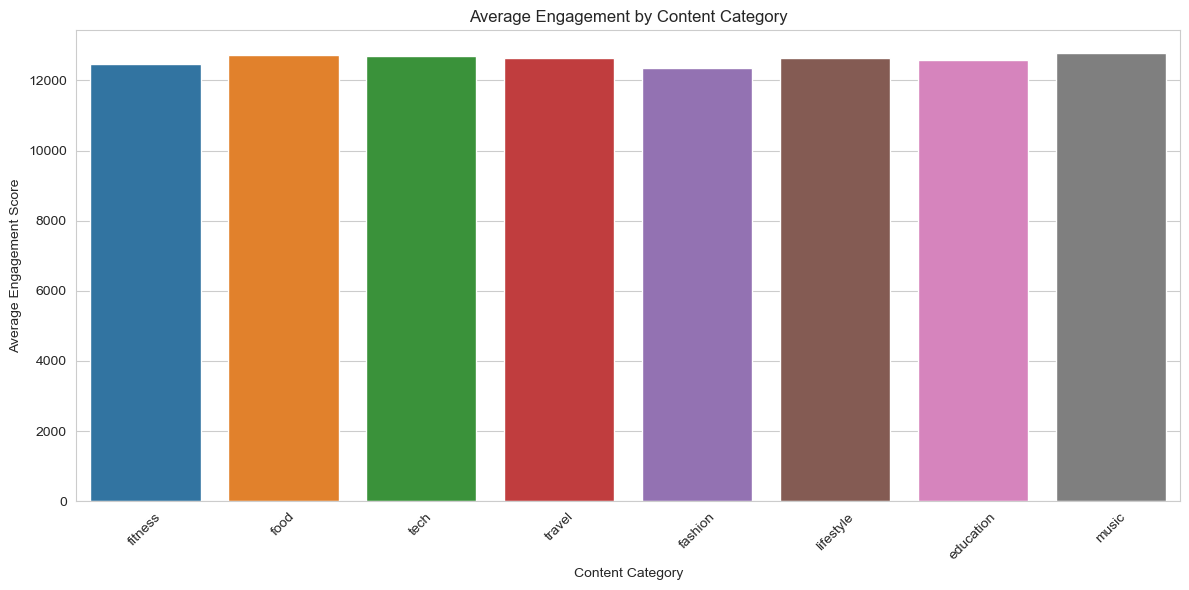

In [94]:
#average engagement by content category
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_clean,
    x='post_category',
    y='engagement_score',
    errorbar=None
)

plt.title('Average Engagement by Content Category')
plt.xlabel('Content Category')
plt.ylabel('Average Engagement Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [96]:
country_engagement = df_clean.groupby('country').agg({
    'engagement_rate': 'mean',
    'engagement_score': 'mean',
    'post_id': 'count'
}).sort_values(
    by='engagement_rate',
    ascending=False
)

country_engagement
country_engagement.head(5)

,engagement_rate,engagement_score,post_id
country,,,
Brazil,1.540704,12385.994048,504
Australia,1.324339,12809.638945,493
France,1.146402,12903.397177,496
UAE,1.112352,12757.791252,503
Canada,0.916659,12605.906433,513


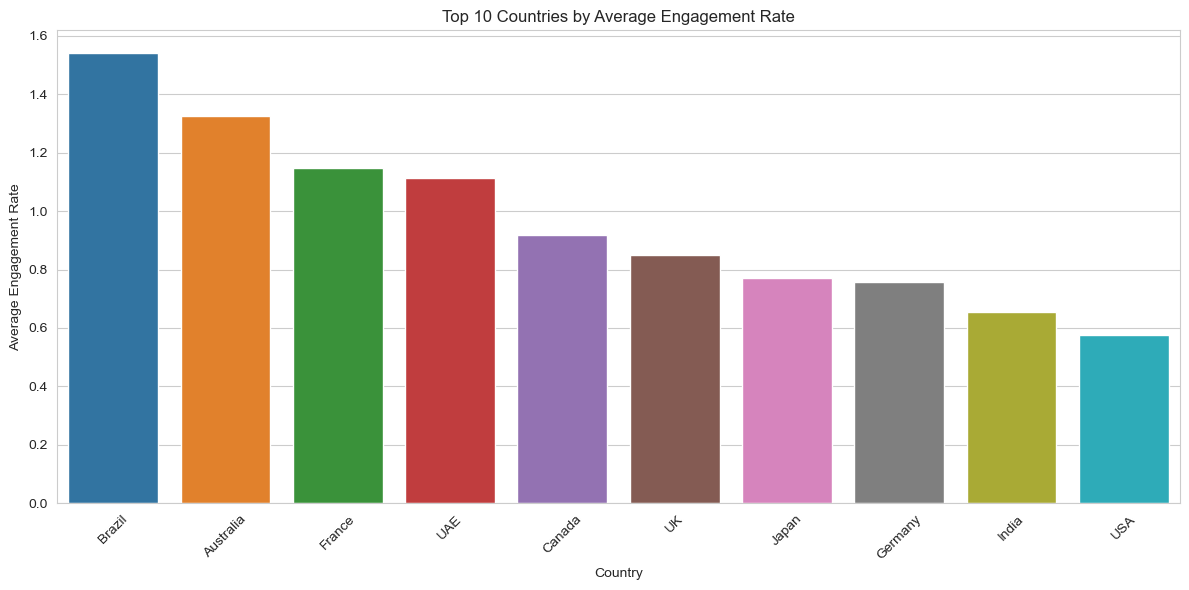

In [98]:
top_countries = country_engagement.head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries,
    x='country',
    y='engagement_rate',
    errorbar=None
)

plt.title('Top 10 Countries by Average Engagement Rate')
plt.xlabel('Country')
plt.ylabel('Average Engagement Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [100]:
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[0, 17, 24, 34, 44, 54, 64, 100],
    labels=[
        'Under 18',
        '18-24',
        '25-34',
        '35-44',
        '45-54',
        '55-64',
        '65+'
    ]
)
age_engagement = df_clean.groupby(
    'age_group',
    observed=False
).agg({
    'engagement_score': 'mean',
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'post_id': 'count'
})

age_engagement

,engagement_score,likes,comments,shares,post_id
age_group,,,,,
Under 18,13104.765625,10616.756696,1494.633929,993.375000,448
18-24,12510.286164,10029.111635,1506.070755,975.103774,636
25-34,12868.015353,10367.407369,1504.276356,996.331627,977
35-44,12677.869526,10144.477190,1516.979015,1016.413321,1096
45-54,12508.520742,9978.922489,1512.439956,1017.158297,916
55-64,12197.989213,9721.944984,1472.556634,1003.487594,927
65+,NaN,NaN,NaN,NaN,0


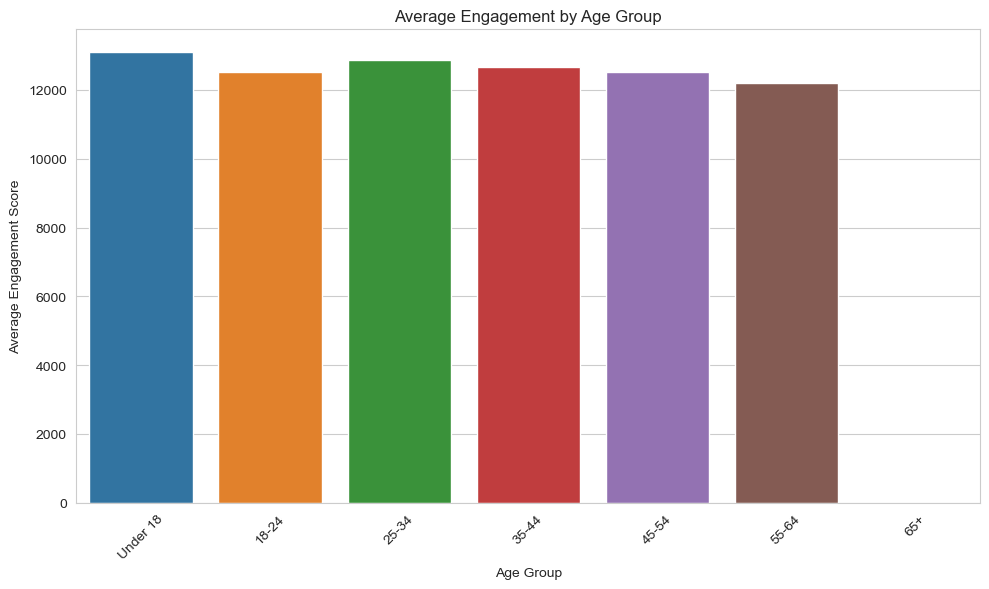

In [101]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_clean,
    x='age_group',
    y='engagement_score',
    errorbar=None
)

plt.title('Average Engagement by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Engagement Score')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

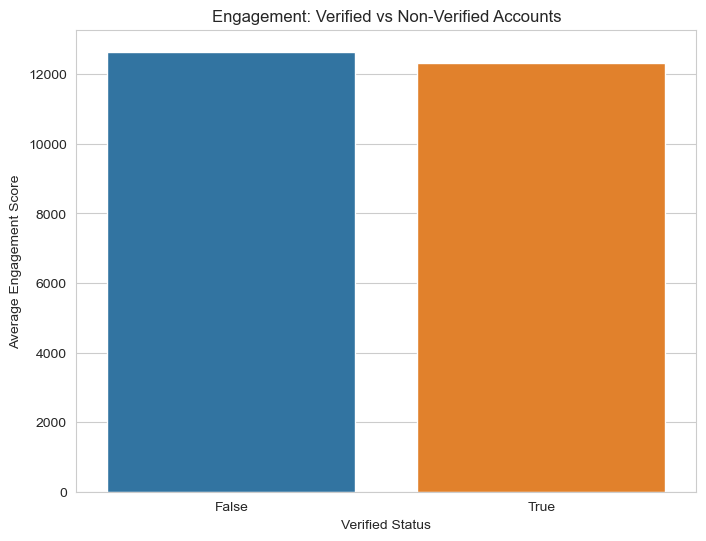

In [102]:
df_clean['is_verified'].value_counts(dropna=False)
plt.figure(figsize=(8, 6))

sns.barplot(
    data=df_clean,
    x='is_verified',
    y='engagement_score',
    errorbar=None
)

plt.title('Engagement: Verified vs Non-Verified Accounts')
plt.xlabel('Verified Status')
plt.ylabel('Average Engagement Score')

plt.show()

In [106]:
#the impact of device type on watch time
device_watch_time = df_clean.groupby('device_type').agg({
    'watch_time_sec': 'mean',
    'engagement_score': 'mean',
    'impression_count': 'mean',
    'post_id': 'count'
}).sort_values(
    by='watch_time_sec',
    ascending=False
)

device_watch_time

,watch_time_sec,engagement_score,impression_count,post_id
device_type,,,,
mobile,4087.830760,12663.208432,49516.948931,1684
tablet,3979.736429,12463.294331,49597.971049,1658
desktop,3974.792521,12708.582027,50934.068758,1658


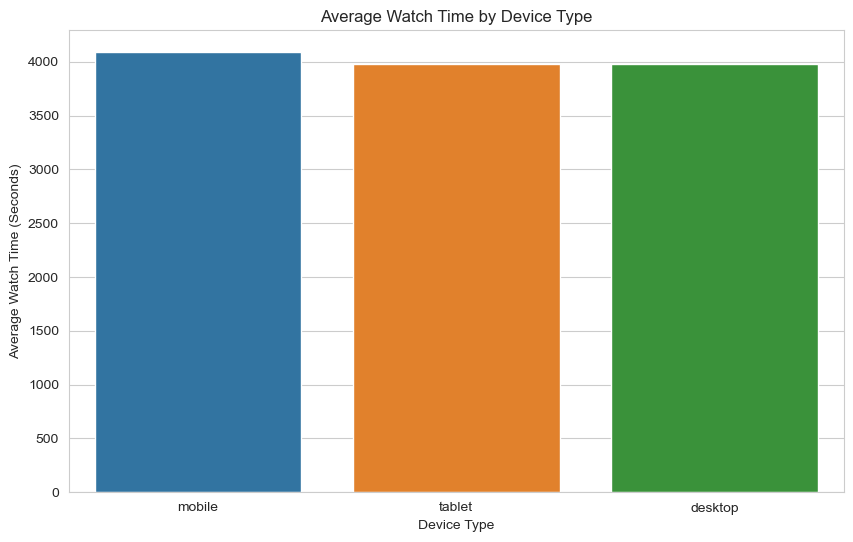

In [107]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_clean,
    x='device_type',
    y='watch_time_sec',
    errorbar=None
)

plt.title('Average Watch Time by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Average Watch Time (Seconds)')

plt.show()

In [108]:
#sentiment performs best
sentiment_performance = df_clean.groupby('sentiment').agg({
    'engagement_score': 'mean',
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean',
    'post_id': 'count'
}).sort_values(
    by='engagement_score',
    ascending=False
)

sentiment_performance

,engagement_score,likes,comments,shares,engagement_rate,post_id
sentiment,,,,,,
negative,12731.514583,10208.112500,1516.094792,1007.307292,1.038486,960
positive,12665.814564,10180.077199,1480.650617,1005.086749,0.919744,2513
neutral,12448.178127,9923.208906,1528.404060,996.565160,0.991170,1527


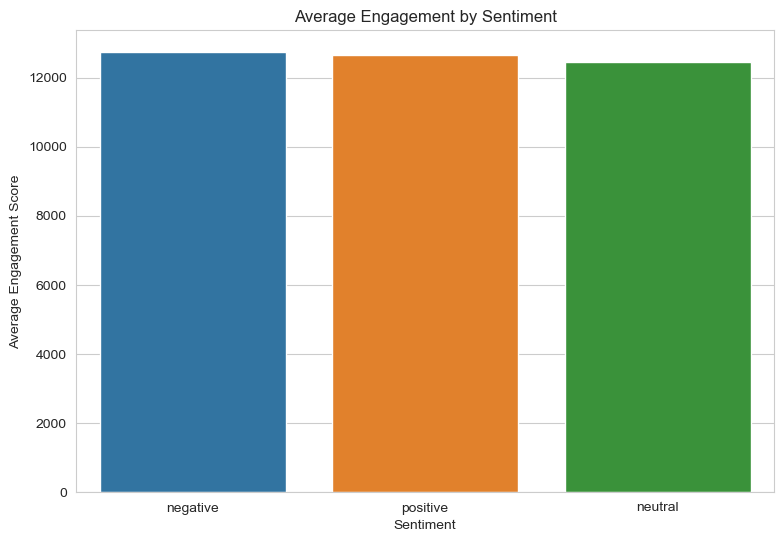

In [109]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=df_clean,
    x='sentiment',
    y='engagement_score',
    errorbar=None
)

plt.title('Average Engagement by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Average Engagement Score')

plt.show()

In [110]:
# Comparison of negative and neutral posts
negative_neutral = df_clean[
    df_clean['sentiment'].isin(['negative', 'neutral'])
]

In [111]:
negative_neutral['sentiment'].value_counts()

sentiment
neutral     1527
negative     960
Name: count, dtype: int64

In [112]:
negative_neutral_summary = negative_neutral.groupby('sentiment').agg({
    'engagement_score': 'mean',
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean',
    'post_id': 'count'
})

negative_neutral_summary

,engagement_score,likes,comments,shares,engagement_rate,post_id
sentiment,,,,,,
negative,12731.514583,10208.112500,1516.094792,1007.307292,1.038486,960
neutral,12448.178127,9923.208906,1528.404060,996.565160,0.991170,1527


In [113]:
negative_neutral.groupby('sentiment')['comments'].mean()

sentiment
negative    1516.094792
neutral     1528.404060
Name: comments, dtype: float64

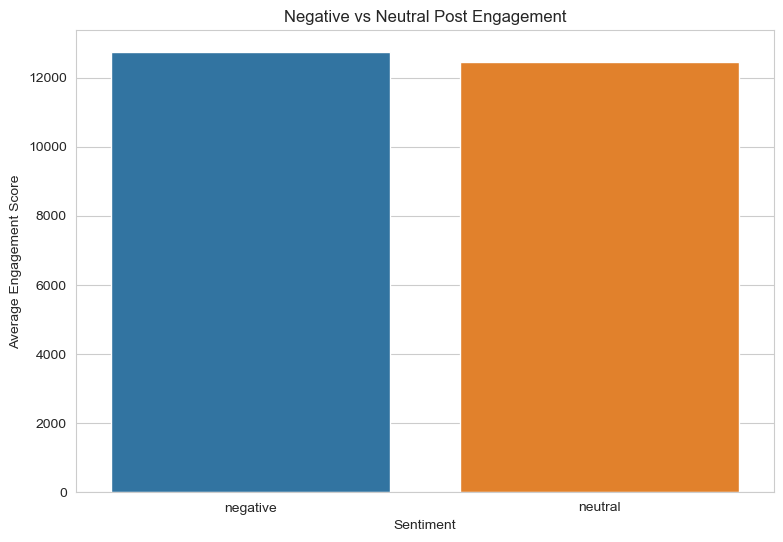

In [114]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=negative_neutral,
    x='sentiment',
    y='engagement_score',
    errorbar=None
)

plt.title('Negative vs Neutral Post Engagement')
plt.xlabel('Sentiment')
plt.ylabel('Average Engagement Score')

plt.show()

Data visualization was performed using Matplotlib, Seaborn and Plotly to identify patterns and relationships within the social media engagement dataset. Matplotlib was used to create scatter plots, line charts, bar charts, pie charts, histograms and box plots. Seaborn was used to generate count plots, statistical bar plots, violin plots, pair plots, correlation heatmaps and swarm plots. Plotly was used to create interactive line, bar, bubble and scatter charts. These visualizations helped examine engagement trends over time, compare post categories, understand demographic distributions, analyse numerical relationships and identify potential outliers. Interactive visualizations also enabled a more detailed exploration of individual data points.

Final Insights and Interpretation

    Content Performance                    
A. Highest-engagement post type found in the chart Average Engagement by Post Type  

The analysis compares the average engagement scores of different post types, including images, videos, reels, and other available formats. The results indicate that Video type receives the highest average engagement.

B. Best-performing content category found in the chart Average Engagement by Content Category

The comparison of engagement across different content categories shows that Music generates the highest average engagement.

C. Countries with highest engagement rate found in the chart Top 10 Countries by Average Engagement Rate	

The country-wise analysis identifies Brazil as having the highest average engagement rates.

    User Trends
A. How age affects engagement found in the chart Average Engagement by Age Group	

The age-group analysis compares average engagement across different audience age groups.
The results show that 'under 18' has the highest average engagement score, while 55-64 age group records comparatively lower engagement.

B. Verified vs non-verified performance found in the chart Engagement: Verified vs Non-Verified	

The analysis compares engagement scores between verified and non-verified accounts.
The results indicate that non-verified accounts generate higher average engagement.

    Behavioural Insights
A. Best time of day for impressions found in the chart Average Impressions by Posting Hour	

The post time of the posts are not provided in the data.

B. Device impact on watch time found in the chart Average Watch Time by Device Type	

The device-wise analysis compares the average watch time of users accessing content through different devices.
The results indicate that users accessing content through Mobile have the highest average watch time.

    Sentiment analysis
A. Best-performing sentiment found in the chart Average Engagement by Sentiment	

The sentiment-based analysis compares engagement across positive, negative, and neutral posts.
The results show that negative sentiments generates the highest average engagement score.

B. Negative vs neutral behaviour found in the chart Negative vs Neutral Post Engagement	

A separate comparison of negative and neutral posts reveals differences in their average likes, comments, shares, and engagement scores. The analysis indicates that negative posts generate higher average engagement, while neutral posts receive comparatively lower engagement.

    Conclusion:

The Social Media Engagement Analytics project demonstrates how Python libraries such as Pandas, NumPy, Matplotlib, Seaborn, and Plotly can be used to analyse social media performance and identify meaningful patterns in audience behaviour.

Through data cleaning, exploratory data analysis, statistical analysis, and visualisation, the project provides insights into content performance, audience demographics, device preferences, and sentiment-based engagement.

The findings can help social media managers make informed decisions about content creation, audience targeting, and publishing strategies. Overall, the analysis highlights the importance of using data-driven approaches to improve social media engagement and optimise digital marketing activities.